# Generating noise

**Noise** is a *row-wise* perturbation of the observed values: each
affected row gets its own random deviation, drawn independently
(in contrast to drift, where one systematic shift is applied to all
affected rows). Use noise to make a pipeline robust to measurement
error, sensor jitter, or rounding — the *signal* is still there, but
each observation is a bit off.

This notebook shows the **two levers** available in badgers:

1. **Acting on the observation process** — add noise directly to the
   observed values (`AdditiveNoiseGenerator`,
   `GaussianNoiseClassesGenerator`). These generators *do not use a
   DGP* and nothing propagates: the value is changed exactly where
   the noise lands.
2. **Acting on the data-generating process (DGP)** — inject noise at a
   node of a *fitted causal model* and let it **propagate** to the
   descendants (`CausalNoiseGenerator`).

Both accept a **selector** to decide which rows are affected
(see the *Understanding badgers* notebook for the selector contract).


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from numpy.random import default_rng
from scipy.stats import norm
from sklearn.datasets import make_blobs

from badgers.generators.tabular_data.noise import AdditiveNoiseGenerator, GaussianNoiseClassesGenerator

rng = default_rng(seed=0)


In [ ]:
def plot_noise(X, cls, Xt):
    """
    Some utility function to generate the plots
    """
    fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))
    axes[0].scatter(X[:, 0], X[:, 1], c=cls, cmap='tab10', s=15)
    axes[1].scatter(Xt[:, 0], Xt[:, 1], c=cls, cmap='tab10', s=15)
    axes[0].set_title('Original')
    axes[1].set_title('Transformed')
    return fig, axes


## Load and prepare data

We first load an existing dataset from `sklearn.datasets`. The class
values are stored as a **column of `X`** (the `y` argument is
deprecated as a data carrier), so plotting uses the explicit vector
`cls`.


In [ ]:
X, y = make_blobs(centers=4, random_state=0, cluster_std=0.25)
# classes are a column of X (y is deprecated as a data carrier)
Xc = np.column_stack([X, y])
column_mapping = {'f0': 0, 'f1': 1, 'cls': 2}
cls = Xc[:, column_mapping['cls']]   # explicit class vector for plotting
print(X.shape, '->', Xc.shape)

## Part A — Acting on the observation process (no DGP)

### Add noise to all values

`AdditiveNoiseGenerator` adds a draw from `distribution` to **every
cell** of `X` — each row gets its own independent deviation.


In [ ]:
trf = AdditiveNoiseGenerator(random_generator=rng)
Xt, _ = trf.generate(X.copy(), None, distribution=norm(scale=0.25))   # y=None (deprecated slot)
print('shapes equal (values changed):', Xt.shape == X.shape)

In [ ]:
fig, axes = plot_noise(X, cls, Xt)


### Add noise per class

`GaussianNoiseClassesGenerator` combines **two independent knobs**
that are easy to confuse:

* the **selector** decides *which rows* receive noise. It returns one
  boolean mask (or deficit probability) per class value. In the demo
  below, `{'cls': {0: 1., 1: 1., 2: 1., 3: 1.}}` means: *every row of
  every class affected with probability 1* — so all rows are noisy. Set
  a value to `0.5` and half of that class's rows would be noisy
  (Bernoulli-wise); set it to `0.` and that class stays clean.
* `noise_std_per_class` decides *how strong* the noise is **on the
  affected rows**, per class: `{0: 0.1, 1: 0.2, 2: 0.3, 3: 0.4}` makes
  class 3 rows four times noisier than class 0 rows. It has **no**
  effect on *which* rows are noisy.

In short: **selector = who is affected, `noise_std_per_class` = how
badly.**

In [ ]:
from badgers.core.selectors import ClassSelector

# WHO is affected: every row of every class is affected (probability 1.0)
selector = ClassSelector('cls', column_mapping, {'cls': {0: 1., 1: 1., 2: 1., 3: 1.}}, rng=rng)

# HOW BADLY: noise std per class value (only applies to affected rows)
trf = GaussianNoiseClassesGenerator(random_generator=rng)
Xt, _ = trf.generate(Xc.copy(), None, selector=selector,
                     noise_std_per_class={0: 0.1, 1: 0.2, 2: 0.3, 3: 0.4})
print('shapes equal (values changed):', Xt.shape == Xc.shape)

In [ ]:
fig, axes = plot_noise(Xc, cls, Xt)


In [ ]:
from badgers.generators.tabular_data.noise.causal import CausalNoiseGenerator
from badgers.core.dgp import OlsDGP


## Part B — Acting on the data-generating process (DGP)

`CausalNoiseGenerator` injects noise at a node of a *fitted causal
model*. The noise perturbs the node's value, and the change
**cascades to the descendants** through the structural equations:
descendant = f(new parent values) + fresh noise. Only downstream nodes
are affected; upstream nodes and untouched rows stay as they were.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from badgers.core.dgp import OlsDGP

In [4]:
def generate_linear_data(graph, n_samples=100, rng=None, coefficients=None):
    """Generate data from a linear structural equation model on a DAG.

    Each edge (u -> v) carries a coefficient w. Every node value is
        v = sum_{u in parents(v)} w_{u,v} * u + noise
    with noise ~ N(0, 1).
    """
    if rng is None:
        rng = np.random.default_rng(42)
    if coefficients is None:
        coefficients = {edge: 1.0 for edge in graph.edges()}

    nodes = list(graph.nodes())
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    X = np.zeros((n_samples, len(nodes)))
    for node in nx.topological_sort(graph):
        idx = node_to_idx[node]
        parents = list(graph.predecessors(node))
        if not parents:
            X[:, idx] = rng.normal(size=n_samples)
        else:
            X[:, idx] = rng.normal(size=n_samples)
            for parent in parents:
                coef = coefficients.get((parent, node), 1.0)
                X[:, idx] += coef * X[:, node_to_idx[parent]]
    return X, {node: i for i, node in enumerate(nodes)}


def draw_graph(graph, title=None):
    """Draw a DAG with fixed left-to-right node positions.

    Nodes are placed in topological generations: roots at x = 0, their
    descendants at x = 1, and so on; siblings are stacked vertically.
    This keeps the visual layout deterministic and consistent across
    all notebooks (no force-directed layout).
    """
    generations = {}  # node -> column index
    for node in nx.topological_sort(graph):
        parents = list(graph.predecessors(node))
        generations[node] = 0 if not parents else max(generations[p] for p in parents) + 1
    columns = {}
    pos = {}
    for node, col in generations.items():
        pos[node] = (col, columns.setdefault(col, 0))
        columns[col] += 1
    # center each column vertically
    height = max(columns.values())
    pos = {node: (x, y - (columns[x] - 1) / 2) for node, (x, y) in pos.items()}
    fig, ax = plt.subplots(1, figsize=(6, 2))
    nx.draw(graph, pos, ax=ax, node_color="lightblue", node_size=800, arrowsize=15)
    nx.draw_networkx_labels(graph, pos, ax=ax)
    if title:
        ax.set_title(title, fontsize=12)
    ax.axis("off")
    return fig


def plot_2panel(X, Xt, yt, x_idx=0, y_idx=1, x_name="X", y_name="Y"):
    """Original | Transformed scatter of two dimensions.

    The transformed panel is coloured by the generator's labels (which rows
    received the defect). Rows with NaN values are drawn as black 'x' markers.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
    axes[0].scatter(X[:, x_idx], X[:, y_idx], color='C0', s=15)
    axes[1].scatter(Xt[:, x_idx], Xt[:, y_idx], color='C1', s=15)
    axes[0].set_title("Original")
    axes[1].set_title("Transformed")
    axes[0].set_xlabel(x_name)
    axes[1].set_xlabel(x_name)
    axes[0].set_ylabel(y_name)
    axes[1].set_ylabel(y_name)
    plt.tight_layout()
    return fig

### 1. Build the causal graph

We use a three-node chain `X -> Y -> Z`. The node names are symbolic;
a `column_mapping` maps them to column positions of `X`.


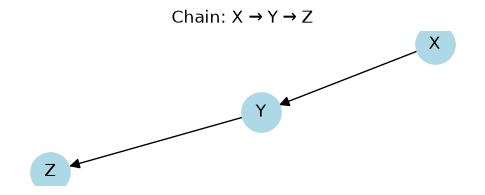

In [5]:
# --- Build the chain X -> Y -> Z ---
chain = nx.DiGraph()
chain.add_edges_from([("X", "Y"), ("Y", "Z")])

draw_graph(chain, title="Chain: X → Y → Z")
plt.show()


### 2. Generate data from the DAG


In [6]:
rng = np.random.default_rng(42)

X, column_mapping = generate_linear_data(
    chain, n_samples=100, rng=rng,
    coefficients={("X", "Y"): 2.0, ("Y", "Z"): 0.5},
)
print(f"X shape: {X.shape}")
print(f"column_mapping: {column_mapping}")


X shape: (100, 3)
column_mapping: {'X': 0, 'Y': 1, 'Z': 2}


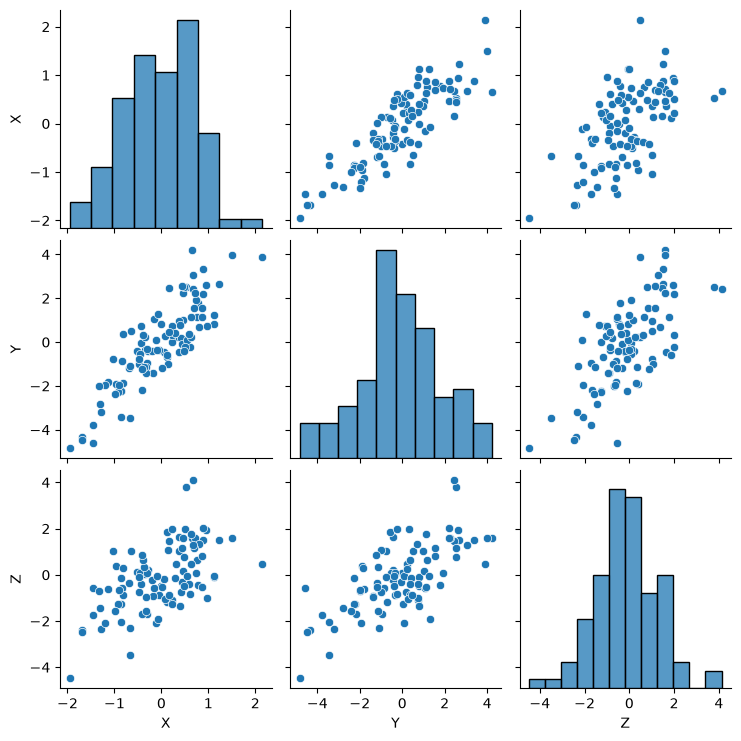

In [7]:
pd.plotting.scatter_matrix(pd.DataFrame(X, columns=column_mapping.keys()), figsize=(8, 8), diagonal='hist')

### 3. Fit the DGP

The default backend `OlsDGP` is a deterministic per-node least-squares
backend (pure NumPy): for every non-root node it learns the linear
coefficients from its parents and the residual noise, fitted on the
*original* data.

In [8]:
dgp = OlsDGP(chain, column_mapping).fit(X.copy())

gen = CausalNoiseGenerator(random_generator=np.random.default_rng(0), dgp=dgp)

### 4. Inject causally-propagated noise

We perturb node `Y` and watch the noise propagate to `Z` (but not to
`X`).

In [9]:
Xt, yt = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    n_copies=1,
    noise_std=0.5,
)
print(f"output shape: {Xt.shape}")


output shape: (100, 3)


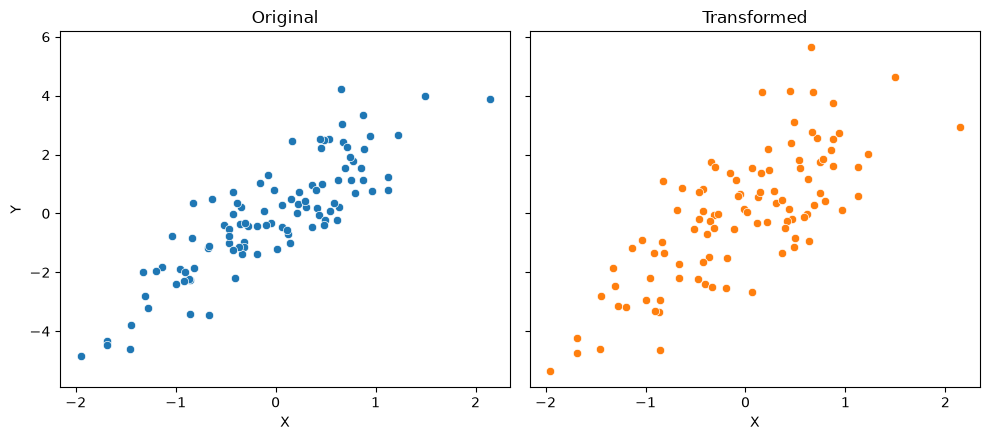

In [11]:
_ = plot_2panel(X, Xt, yt, x_name='X', y_name='Y')

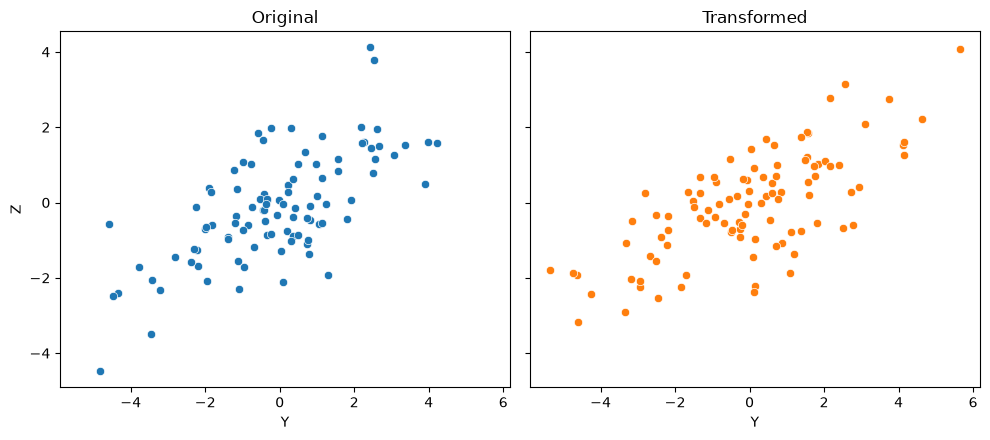

In [12]:
_ = plot_2panel(X, Xt, yt, x_idx=1, y_idx=2, x_name='Y', y_name='Z')

### Expanding rows (`n_copies`)

Set `n_copies > 1` to *expand* the data: each original row produces
`n_copies` noisy copies. Shape grows (appending mode).

expanded shape: (300, 3)  (from 100 rows)


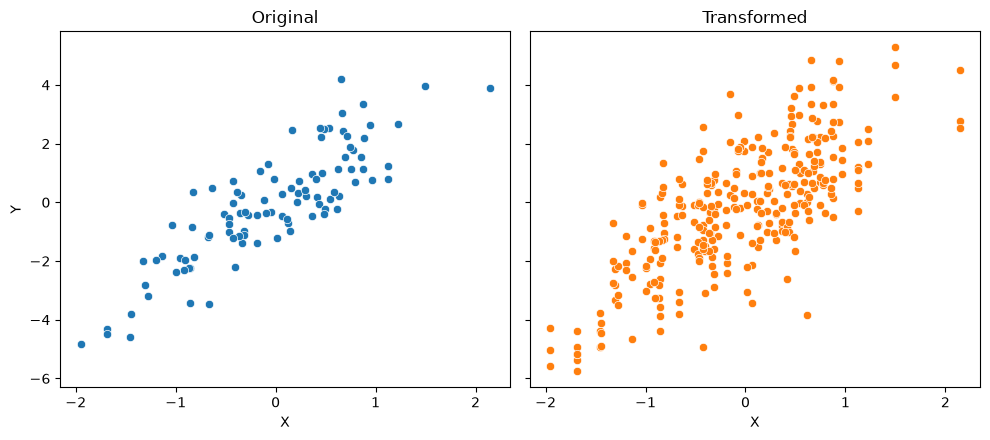

In [13]:
Xt_exp, yt_exp = gen.generate(
    X.copy(), y=None,
    perturbation_nodes=["Y"],
    n_copies=3,
    noise_std=0.5,
)
print(f"expanded shape: {Xt_exp.shape}  (from {X.shape[0]} rows)")
_ = plot_2panel(X, Xt_exp, yt_exp, x_name='X', y_name='Y')


## Summary

| Lever | Generator | Uses a DGP? | Propagates? | Selector support ||---|---|---|---|---|
| observation process | `AdditiveNoiseGenerator` | no | no (values only) | — || observation process, per class | `GaussianNoiseClassesGenerator` | no | no (values only) | `ClassSelector` || DGP | `CausalNoiseGenerator` | **yes** (fitted) | **yes** — descendants re-evaluated | yes |
* Noise is *row-wise*: each affected row draws its own deviation —
  in contrast to drift, where one systematic shift hits all rows.
* **selector = who is affected** (masks/probabilities per class),
  **`noise_std_per_class` = how strongly** (magnitude per class).
* Causal noise mutates `X` in place — pass `X.copy()` to keep the
  original.
